# Lab 10-09 · Real Op-Amps: Non-Idealities

Companion to [chapter 10-09](../../chapters/10-09-real-op-amps-nonidealities.md). Predict first; the `assert` lines check against the answer keys. Data-sheet values are those quoted in the chapter.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

def closed_loop(f, a0_db, gbw, noise_gain):
    a0 = 10 ** (a0_db / 20)
    a = a0 / (1 + 1j * f / (gbw / a0))
    return a / (1 + a / noise_gain)

## Part 1 · In-band error

*Predict first:* the 0.1% bandwidth of a TLV9062 (130 dB, 10 MHz) at a noise gain of 10.

0.1% bandwidth: 44.755 kHz


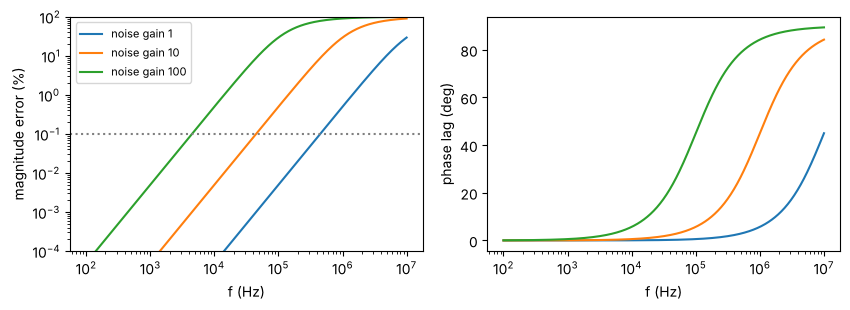

In [2]:
dc = abs(closed_loop(0.0, 130, 10e6, 10))
f01 = brentq(lambda f: abs(closed_loop(f, 130, 10e6, 10)) / dc - 0.999, 1, 1e7)
print(f"0.1% bandwidth: {f01/1e3:.3f} kHz")
assert abs(f01 / 1e3 - 44.755) < 5e-4
f = np.logspace(2, 7, 400)
fig, (a, b) = plt.subplots(1, 2, figsize=(8.6, 3.2))
for g in (1, 10, 100):
    h = closed_loop(f, 130, 10e6, g)
    h0 = abs(closed_loop(0.0, 130, 10e6, g))
    a.loglog(f, np.maximum(1 - np.abs(h) / h0, 1e-9) * 100, label=f"noise gain {g}")
    b.semilogx(f, -np.degrees(np.angle(h)), label=f"noise gain {g}")
a.axhline(0.1, ls=":", color="0.5"); a.set_ylim(1e-4, 100); a.set_xlabel("f (Hz)"); a.set_ylabel("magnitude error (%)"); a.legend(fontsize=8)
b.set_xlabel("f (Hz)"); b.set_ylabel("phase lag (deg)"); fig.tight_layout(); plt.show()

## Part 2 · A slew-limited sine (guided exercise)

TLV9062 follower: 10 MHz bandwidth, 6.5 V/µs, 2.5 V peak at 800 kHz. *Predict first:* the output amplitude.

slew-limited peak 1.9824 V; linear model 2.4920 V


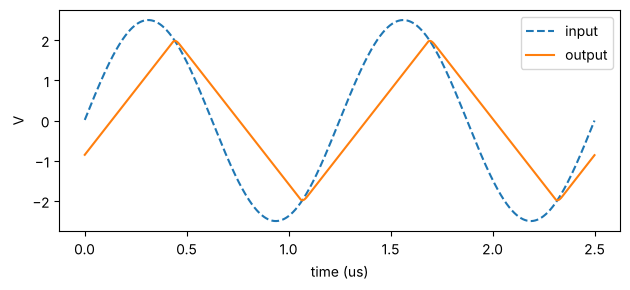

In [3]:
SR, tau, f0, vp = 6.5e6, 1 / (2 * math.pi * 10e6), 800e3, 2.5

def rhs(t, y):
    return [np.clip((vp * math.sin(2 * math.pi * f0 * t) - y[0]) / tau, -SR, SR)]

T = 1 / f0
t = np.linspace(0, 20 * T, 20001)
sol = solve_ivp(rhs, (0, 20 * T), [0.0], t_eval=t, max_step=T / 2000)
steady = sol.y[0][t > 15 * T]
peak = steady.max()
lin = vp / math.sqrt(1 + (f0 / 10e6) ** 2)
print(f"slew-limited peak {peak:.4f} V; linear model {lin:.4f} V")
assert abs(peak - 1.982) < 5e-4 and abs(lin - 2.492) < 5e-4
sel = t > 18 * T
plt.figure(figsize=(6.4, 3.0))
plt.plot((t[sel] - 18 * T) * 1e6, vp * np.sin(2 * np.pi * f0 * t[sel]), "--", label="input")
plt.plot((t[sel] - 18 * T) * 1e6, sol.y[0][sel], label="output")
plt.xlabel("time (us)"); plt.ylabel("V"); plt.legend(); plt.tight_layout(); plt.show()

## Part 3 · A DC error budget for the bridge

350 Ω arms (each input sees about 175 Ω), 2.5 V common mode on a 5 V supply, 0.1 V supply variation, 25 to 125 °C. Guaranteed values where given; the TLV9062's drift is typical only. Both data sheets specify $V_{OS}$ at $V_{CM} = V_S/2$, so the offset already includes the common-mode error at that point: the CMRR term must use only the *departure* of the common mode from the test condition, which here is zero (and stays zero when the excitation and the supply move together).

In [4]:
def budget(vos, drift, ib, cmrr_db, psrr, vcm=2.5, vs=5.0):
    terms = {"offset at 25 C": vos, "drift x 100 C": drift * 100, "I_B x 175 ohm": ib * 175,
             "CMRR, V_CM - V_S/2": abs(vcm - vs / 2) * 10 ** (-cmrr_db / 20), "PSRR x 0.1 V": 0.1 * psrr}
    worst = sum(abs(x) for x in terms.values())
    rss = math.sqrt(sum(x * x for x in terms.values()))
    return terms, worst, rss

for name, args in (("OPA333", (10e-6, 0.05e-6, 200e-12, 106, 5e-6)),
                   ("TLV9062", (1.6e-3, 0.53e-6, 0.5e-12, 80, 80e-6))):
    terms, worst, rss = budget(*args)
    print(name, {k: f"{v*1e6:.3f} uV" for k, v in terms.items()})
    print(f"   worst {worst*1e6:.2f} uV, RSS {rss*1e6:.2f} uV")
_, w1, r1 = budget(10e-6, 0.05e-6, 200e-12, 106, 5e-6)
_, w2, r2 = budget(1.6e-3, 0.53e-6, 0.5e-12, 80, 80e-6)
assert abs(w1 * 1e6 - 15.535) < 5e-4 and abs(r1 * 1e6 - 11.19) < 5e-3
assert abs(w2 * 1e3 - 1.661) < 5e-4 and abs(r2 * 1e3 - 1.601) < 5e-4
# had the CMRR term been charged at the full 2.5 V common mode, the OPA333 total would have read
_, w1x, _ = budget(10e-6, 0.05e-6, 200e-12, 106, 5e-6, vcm=2.5, vs=0.0)
print(f"double-counted CMRR would give {w1x*1e6:.2f} uV for the OPA333")

OPA333 {'offset at 25 C': '10.000 uV', 'drift x 100 C': '5.000 uV', 'I_B x 175 ohm': '0.035 uV', 'CMRR, V_CM - V_S/2': '0.000 uV', 'PSRR x 0.1 V': '0.500 uV'}
   worst 15.54 uV, RSS 11.19 uV
TLV9062 {'offset at 25 C': '1600.000 uV', 'drift x 100 C': '53.000 uV', 'I_B x 175 ohm': '0.000 uV', 'CMRR, V_CM - V_S/2': '0.000 uV', 'PSRR x 0.1 V': '8.000 uV'}
   worst 1661.00 uV, RSS 1600.90 uV
double-counted CMRR would give 28.06 uV for the OPA333


## Part 4 · Figures of merit

In [5]:
parts = {"TLV9062": (10.0, 0.538), "OPA333": (0.35, 0.017), "OPA1611": (40.0, 3.6)}   # GBW (MHz), I_Q (mA)
fom = {k: g / i for k, (g, i) in parts.items()}
for k, v in fom.items():
    print(f"{k:8s}: {v:6.2f} MHz/mA")
assert abs(fom["TLV9062"] - 18.59) < 5e-3 and abs(fom["OPA333"] - 20.59) < 5e-3 and abs(fom["OPA1611"] - 11.11) < 5e-3

TLV9062 :  18.59 MHz/mA
OPA333  :  20.59 MHz/mA
OPA1611 :  11.11 MHz/mA
